In [4]:
import os
import keras
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [5]:
# Load Dataset
PATH = "dataset/"
CLASS_NAMES = os.listdir(PATH)
print("Classes: ", CLASS_NAMES)

Classes:  ['Cucumber', 'Broccoli', 'Tomato', 'Carrot']


In [6]:
# Load Image
rows, cols = 224, 224

x, y = [],[]

counter = 0

for class_name in CLASS_NAMES:
    for img_name in os.listdir(PATH + class_name):
        path = f"{PATH}{class_name}/{img_name}"
        label = counter
        image = tf.keras.preprocessing.image.load_img(path, target_size=(rows, cols), color_mode="grayscale")
        image = tf.keras.preprocessing.image.img_to_array(image)
        x.append(image)
        y.append(label)
    counter += 1
    print(class_name)

x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

print("x: ", x.shape)
print("y: ", y.shape)

Cucumber
Broccoli
Tomato
Carrot
x:  (2000, 224, 224, 1)
y:  (2000,)


In [ ]:
# Splitting
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, shuffle=True, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [8]:
# Preprocessing OHE
y_train = keras.utils.to_categorical(y_train, num_classes=4)
y_val = keras.utils.to_categorical(y_val, num_classes=4)
y_test = keras.utils.to_categorical(y_test, num_classes=4)

In [9]:
# DCNN Model Architecture
model = keras.Sequential([
    # Input Layer
    keras.layers.Input(shape=(rows, cols, 1)),

    # Hidden layer: feature extraction
    keras.layers.Conv2D(6, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),
    keras.layers.Flatten(),

    # Output layer: ReLu + Softmax
    keras.layers.Dense(120, activation="relu"),
    keras.layers.Dense(4, activation="softmax"),
])

model.summary()

2026-10-11 22:27:10.302235: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-10-11 22:27:10.302354: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-10-11 22:27:10.302360: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-10-11 22:27:10.303103: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-11 22:27:10.303773: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 220, 220, 6)    │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 106, 106, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 102, 102, 16)   │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 51, 51, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │     4,994,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           484 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,003,512 (19.09 MB)

 Trainable params: 5,003,512 (19.09 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=10, batch_size=32)

Epoch 1/10


2026-10-11 22:27:12.272149: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.2850 - loss: 2.1164 - val_accuracy: 0.3850 - val_loss: 1.2608
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.5288 - loss: 1.1127 - val_accuracy: 0.4950 - val_loss: 1.2708
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.7206 - loss: 0.7468 - val_accuracy: 0.5950 - val_loss: 1.2082
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.7912 - loss: 0.5514 - val_accuracy: 0.6000 - val_loss: 1.1377
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - accuracy: 0.8625 - loss: 0.3924 - val_accuracy: 0.5800 - val_loss: 1.8474
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.8794 - loss: 0.3544 - val_accuracy: 0.5500 - val_loss: 2.6333
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.8163 - loss: 0.6328 - val_accuracy: 0.5350 - val_loss: 2.5725
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.8712 - loss: 0.4825 - val_accuracy: 0.5100 - val_loss

In [11]:
# Model Evaluation
model.evaluate(x_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6450 - loss: 10.5432


[10.543195724487305, 0.6449999809265137]

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


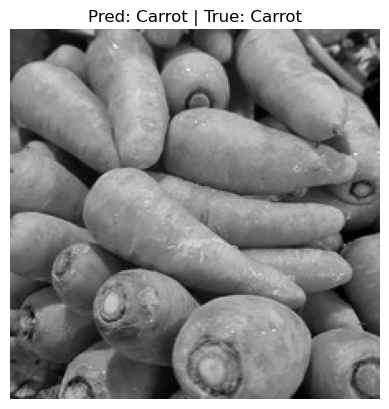

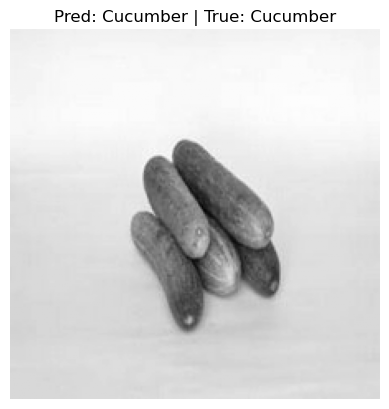

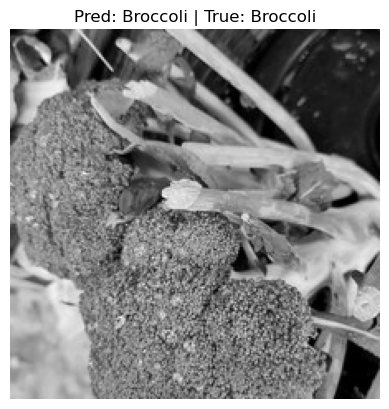

In [15]:
pred_result = model.predict(x_test)

# Tampilkan gambar test ke-0 sampai ke-8 (ganti range sesuai kebutuhan, misal range(20, 30))
for i in range(0, 3):
    pred = CLASS_NAMES[np.argmax(pred_result[i])]   # kelas prediksi
    true = CLASS_NAMES[np.argmax(y_test[i])]        # kelas asli (y_test masih one-hot)

    plt.imshow(x_test[i].squeeze(), cmap="gray")    # squeeze: (224, 224, 1) -> (224, 224)
    plt.title(f"Pred: {pred} | True: {true}")
    plt.axis("off")
    plt.show()

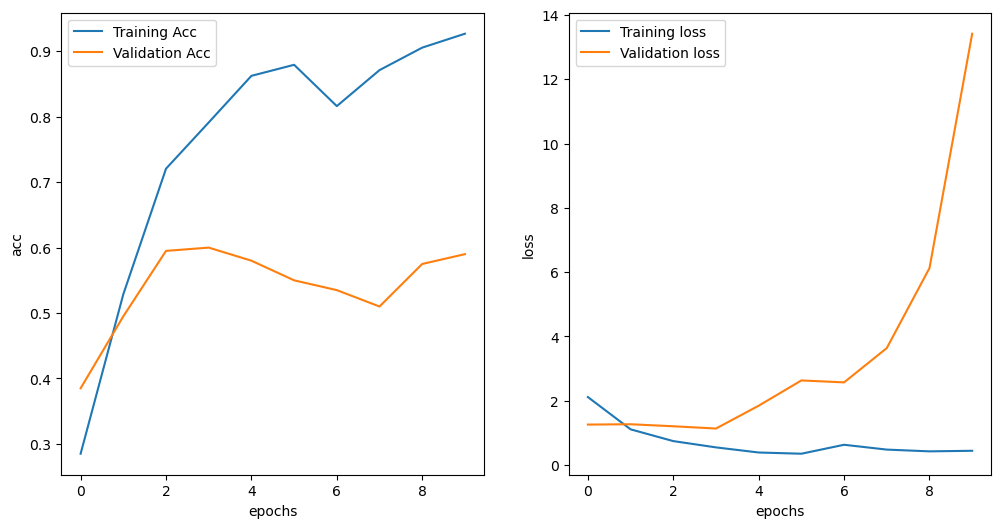

In [13]:
# Plot Evaluation Metrics
plt.figure(figsize=(12, 6))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Acc')
plt.plot(history.history['val_accuracy'], label='Validation Acc')
plt.xlabel('epochs')
plt.ylabel('acc')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()

plt.show()